# 03 · Facility Location

**Where to open warehouses and which customers each serves is not a map-reading
exercise — it is a capacitated facility-location MILP.** Trade the fixed cost of
opening a site against the transportation cost of serving demand from it:

- binary decisions: open site *i* or not (fixed cost),
- continuous decisions: ship units from open sites to customers (capacity-limited),
- minimize total fixed + transportation cost.

We solve it to exact optimality with an open solver (CBC), **verify against brute
force** at this size, contrast with the intuitive nearest-site heuristic, and read the
**capacity shadow prices** that say which facility to expand next.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from src.config import SETTINGS
from src.network.facility_location import (
    brute_force_facility_location,
    capacity_shadow_prices,
    nearest_site_cost,
    solve_facility_location,
)
from src.outputs import save_figure, save_json

plt.rcParams["figure.figsize"] = (7, 5)
rng = np.random.default_rng(SETTINGS.seed)
n_sites = SETTINGS.facility_location.n_sites
n_customers = SETTINGS.facility_location.n_customers

## A candidate network

Candidate sites and customers on a 100×100 map. Transport cost per unit is the
Euclidean distance; total capacity is ~1.6× total demand, so no single site can serve
everyone and the solver must choose a set.

In [2]:
site_xy = rng.uniform(0.0, 100.0, (n_sites, 2))
customer_xy = rng.uniform(0.0, 100.0, (n_customers, 2))
demands = rng.uniform(20.0, 60.0, n_customers)
fixed_costs = rng.uniform(800.0, 1500.0, n_sites)
transport = np.sqrt(((site_xy[:, None, :] - customer_xy[None, :, :]) ** 2).sum(axis=2))
capacities = rng.uniform(150.0, 300.0, n_sites)
capacities = capacities * (demands.sum() / capacities.sum()) * 1.6

save_json(
    {
        "site_xy": site_xy,
        "customer_xy": customer_xy,
        "demands": demands,
        "fixed_costs": fixed_costs,
        "capacities": capacities,
        "transport_cost": transport,
    },
    "03_inputs",
)
print(f"{n_sites} sites, {n_customers} customers, total demand {demands.sum():.0f}, "
      f"total capacity {capacities.sum():.0f}")

5 sites, 8 customers, total demand 310, total capacity 496


## Solve the MILP to exact optimality

In [3]:
solution = solve_facility_location(fixed_costs, capacities, demands, transport)
save_json(solution, "03_solution")

print(f"status          : {solution.status}")
print(f"open sites      : {solution.opened}")
print(f"fixed cost      : {solution.fixed_cost:.1f}")
print(f"transport cost  : {solution.transport_cost:.1f}")
print(f"total cost      : {solution.total_cost:.1f}")

status          : Optimal
open sites      : (0, 1, 2, 4)
fixed cost      : 3911.1
transport cost  : 8093.2
total cost      : 12004.3


## Verify against brute force

At this size we can enumerate every subset of sites to open, solve the transportation
LP for each, and confirm the MILP found the global optimum.

In [4]:
brute_opened, brute_cost = brute_force_facility_location(fixed_costs, capacities, demands, transport)
match = abs(brute_cost - solution.total_cost) < 1e-4
save_json({"brute_opened": list(brute_opened), "brute_cost": brute_cost,
           "milp_cost": solution.total_cost, "match": bool(match)}, "03_brute_force_check")
print(f"brute-force optimum: sites {brute_opened}, cost {brute_cost:.1f}")
print(f"MILP optimum       : sites {solution.opened}, cost {solution.total_cost:.1f}")
print(f"match: {match}")

brute-force optimum: sites (0, 1, 2, 4), cost 12004.3
MILP optimum       : sites (0, 1, 2, 4), cost 12004.3
match: True


## The optimal network

Opened sites in teal, closed candidates hollow, customers as dots. Lines show who each
open site serves (width ∝ units shipped).

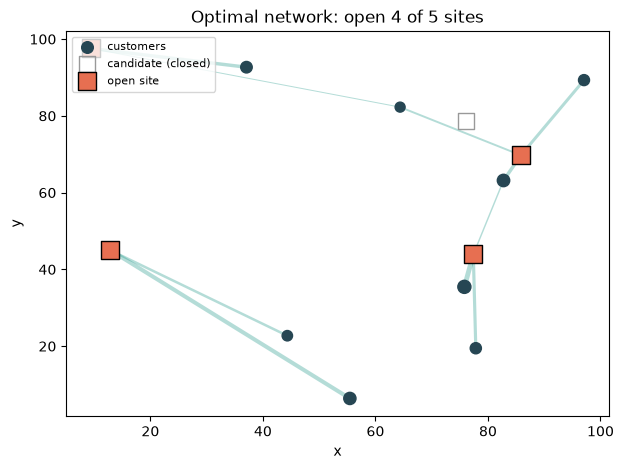

In [5]:
fig, ax = plt.subplots()
for i in range(n_sites):
    for j in range(n_customers):
        flow = solution.assignment[i, j]
        if flow > 1e-6:
            ax.plot([site_xy[i, 0], customer_xy[j, 0]], [site_xy[i, 1], customer_xy[j, 1]],
                    color="#2a9d8f", alpha=0.35, linewidth=0.5 + 3.0 * flow / demands.max(), zorder=1)
ax.scatter(customer_xy[:, 0], customer_xy[:, 1], s=30 + demands, color="#264653", zorder=2, label="customers")
closed = [i for i in range(n_sites) if i not in solution.opened]
if closed:
    ax.scatter(site_xy[closed, 0], site_xy[closed, 1], marker="s", s=140,
               facecolors="none", edgecolors="#999", zorder=3, label="candidate (closed)")
ax.scatter(site_xy[list(solution.opened), 0], site_xy[list(solution.opened), 1], marker="s",
           s=160, color="#e76f51", edgecolors="black", zorder=4, label="open site")
ax.set_title(f"Optimal network: open {len(solution.opened)} of {n_sites} sites")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "03_network_map")
plt.show()

## The cost of the guess: nearest-site assignment

The intuitive baseline serves each customer from its nearest site (overflowing on
capacity) and pays the fixed cost of whatever sites that uses. It is a feasible plan, so
it can never beat the optimum — the gap is money left on the table.

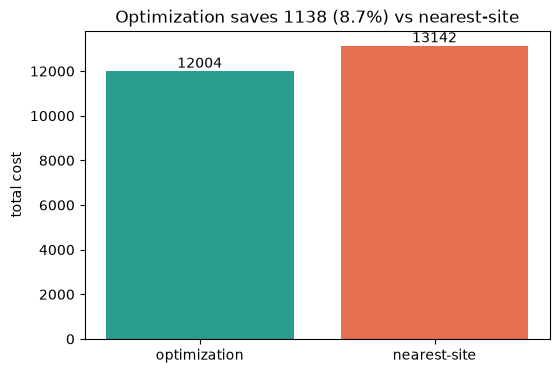

optimal total     : 12004.3
nearest-site total: 13141.8
savings           : 1137.6


In [6]:
naive = nearest_site_cost(fixed_costs, capacities, demands, transport)
savings = naive - solution.total_cost
save_json({"optimal_total": solution.total_cost, "nearest_site_total": naive, "savings": savings},
          "03_nearest_site_gap")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["optimization", "nearest-site"], [solution.total_cost, naive],
              color=["#2a9d8f", "#e76f51"])
ax.bar_label(bars, fmt="%.0f")
ax.set_ylabel("total cost")
ax.set_title(f"Optimization saves {savings:.0f} ({savings / naive:.1%}) vs nearest-site")
save_figure(fig, "03_cost_vs_nearest_site")
plt.show()
print(f"optimal total     : {solution.total_cost:.1f}")
print(f"nearest-site total: {naive:.1f}")
print(f"savings           : {savings:.1f}")

## Capacity shadow prices: which site to expand next

Fix the open/close decision, re-solve the LP, and read the dual of each capacity
constraint. A large shadow price means an extra unit of capacity *there* is worth a lot
— that is the site to expand.

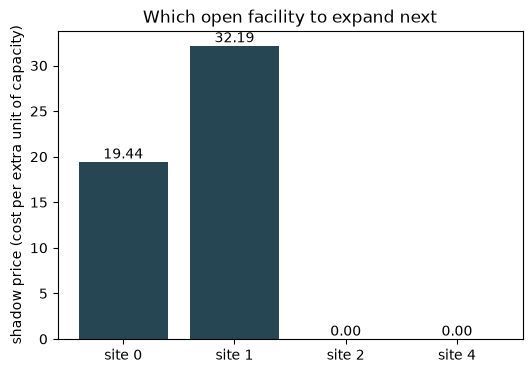

{0: 19.439925, 1: 32.188239, 2: 0.0, 4: 0.0}

In [7]:
prices = capacity_shadow_prices(fixed_costs, capacities, demands, transport)
save_json({str(site): value for site, value in prices.items()}, "03_capacity_shadow_prices")

fig, ax = plt.subplots(figsize=(6, 4))
sites = list(prices)
bars = ax.bar([f"site {s}" for s in sites], [prices[s] for s in sites], color="#264653")
ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("shadow price (cost per extra unit of capacity)")
ax.set_title("Which open facility to expand next")
save_figure(fig, "03_capacity_shadow_prices")
plt.show()
prices

## Takeaway

Facility location is a MILP with an exact answer: the precise set of sites to open and
the precise assignment of demand, minimizing fixed plus transportation cost. It beats
the nearest-site heuristic by a measurable amount, and its capacity shadow prices hand
you the expansion strategy for free. Optimization produces both the plan **and** the
strategy.

In [8]:
takeaways = {
    "thesis": "Facility location is a MILP; it beats nearest-site and its duals say what to expand.",
    "open_sites": list(solution.opened),
    "optimal_cost": round(solution.total_cost, 1),
    "savings_vs_nearest_site": round(savings, 1),
    "matches_brute_force": bool(match),
    "site_to_expand": max(prices, key=prices.get) if prices else None,
}
save_json(takeaways, "03_takeaways")
takeaways

{'thesis': 'Facility location is a MILP; it beats nearest-site and its duals say what to expand.',
 'open_sites': [0, 1, 2, 4],
 'optimal_cost': 12004.3,
 'savings_vs_nearest_site': 1137.6,
 'matches_brute_force': True,
 'site_to_expand': 1}